In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Metadata

In [127]:
device = 'cpu'

# Read train data

In [128]:
ddf = pd.read_csv('../data/data_C/train_signals.csv')
ddf.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   string  4500 non-null   str  
 1   source  4500 non-null   int64
dtypes: int64(1), str(1)
memory usage: 70.4 KB


## check if quality is OK

In [129]:
ddf['source'].value_counts(dropna=False, normalize=True)

source
1    0.335556
0    0.335111
2    0.329333
Name: proportion, dtype: float64

In [130]:
ddf['string'].map(len).value_counts(dropna=False) 

string
28    4500
Name: count, dtype: int64

In [131]:
char_set = set()

for row in ddf['string']:
    char_set = char_set | set([ch for ch in row])

char_set

{'A', 'B', 'C', 'D', 'E', 'F'}

# Torch dataset and data-loader for train data split into train and validation

In [132]:

class LettersDataset(Dataset):

    def __init__(self, dataframe):

        self.letter_to_idx = {
            'A': 0,
            'B': 1,
            'C': 2,
            'D': 3,
            'E': 4,
            'F': 5
        }

        strings = dataframe['string'].tolist()

        # Преобразуем буквы в индексы
        indices = torch.tensor([
            [self.letter_to_idx[ch] for ch in s]
            for s in strings
        ], dtype=torch.long)

        # One-Hot Encoding: (N, 28, 6)
        self.X = torch.nn.functional.one_hot(
            indices,
            num_classes=6
        ).float()

        # Целевые классы: (N,)
        self.y = torch.tensor(
            dataframe['source'].values,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [133]:
train_df, valid_df = train_test_split(
    ddf,
    test_size=0.2,
    random_state=42,
    stratify=ddf['source']
)

In [134]:
train_dataset = LettersDataset(train_df)
valid_dataset = LettersDataset(valid_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False
)

# MLP class

In [135]:
class MLP(nn.Module):

    def __init__(self, input_size=168, num_classes=3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(input_size, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)

## AdamW optimizer with Weight Decay

In [136]:
model = MLP().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

In [137]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=4,
    threshold=0.001,
    min_lr=1e-6
)

# Training MLP model

## one epoch run function

In [138]:

def run_epoch(model, loader, criterion, device, optimizer=None):

    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            if is_train:
                loss.backward()
                optimizer.step()

        batch_size = y_batch.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == y_batch).sum().item()

        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    epoch_acc = total_correct / total_samples

    return epoch_loss, epoch_acc


## training cycle run function

In [139]:

def fit(
    model,
    train_loader,
    valid_loader,
    criterion,
    optimizer,
    device,
    epochs=100,
    patience=10,
    checkpoint_path='../models/best_model.torch_save',
    scheduler=None
):

    best_valid_loss = float('inf')
    best_valid_acc = 0.0
    epochs_without_improvement = 0

    history = {
        'train_loss': [],
        'train_acc': [],
        'valid_loss': [],
        'valid_acc': []
    }

    for epoch in range(epochs):

        train_loss, train_acc = run_epoch(
            model,
            train_loader,
            criterion,
            device,
            optimizer
        )

        valid_loss, valid_acc = run_epoch(
            model,
            valid_loader,
            criterion,
            device
        )

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)

        history['valid_loss'].append(valid_loss)
        history['valid_acc'].append(valid_acc)

        # Проверяем улучшение validation loss
        if valid_loss < best_valid_loss:

            best_valid_loss = valid_loss
            epochs_without_improvement = 0

            torch.save(model.state_dict(), checkpoint_path)

            status = '*'

        else:
            epochs_without_improvement += 1
            status = ''

        # Добавим второй checkpoint:
        if valid_acc > best_valid_acc:
            best_valid_acc = valid_acc
            torch.save(model.state_dict(), '../models/best_accuracy_model.torch_save')

        print(
            f"Epoch [{epoch + 1:03d}/{epochs:03d}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_acc:.4f} "
            f"| Valid Loss: {valid_loss:.4f} "
            f"| Valid Acc: {valid_acc:.4f} "
            f"| LR: {(optimizer.param_groups[0]['lr']):.7f} "
            f"{status}"
        )

        # В fit() после расчёта Validation Loss:
        if scheduler is not None:
            scheduler.step(valid_loss)               # added here

        # Early Stopping
        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping at epoch {epoch + 1}")
            break

    # Загружаем лучшую модель
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )

    print(f"\nBest validation loss: {best_valid_loss:.4f}")

    return model, history


## run training

In [140]:
model, history = fit(
    model=model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=100,
    patience=10
)

Epoch [001/100] | Train Loss: 1.1161 | Train Acc: 0.3616 | Valid Loss: 1.0792 | Valid Acc: 0.4222 | LR: 0.0010000 *
Epoch [002/100] | Train Loss: 1.0420 | Train Acc: 0.4515 | Valid Loss: 1.0173 | Valid Acc: 0.5122 | LR: 0.0010000 *
Epoch [003/100] | Train Loss: 0.9685 | Train Acc: 0.5357 | Valid Loss: 0.9505 | Valid Acc: 0.5500 | LR: 0.0010000 *
Epoch [004/100] | Train Loss: 0.8847 | Train Acc: 0.5787 | Valid Loss: 0.8431 | Valid Acc: 0.6067 | LR: 0.0010000 *
Epoch [005/100] | Train Loss: 0.8111 | Train Acc: 0.6253 | Valid Loss: 0.7593 | Valid Acc: 0.6389 | LR: 0.0010000 *
Epoch [006/100] | Train Loss: 0.7382 | Train Acc: 0.6504 | Valid Loss: 0.7030 | Valid Acc: 0.6533 | LR: 0.0010000 *
Epoch [007/100] | Train Loss: 0.7134 | Train Acc: 0.6691 | Valid Loss: 0.6746 | Valid Acc: 0.6700 | LR: 0.0010000 *
Epoch [008/100] | Train Loss: 0.6493 | Train Acc: 0.6964 | Valid Loss: 0.6541 | Valid Acc: 0.6889 | LR: 0.0010000 *
Epoch [009/100] | Train Loss: 0.6282 | Train Acc: 0.7213 | Valid Loss: 0

## see training history on graphs

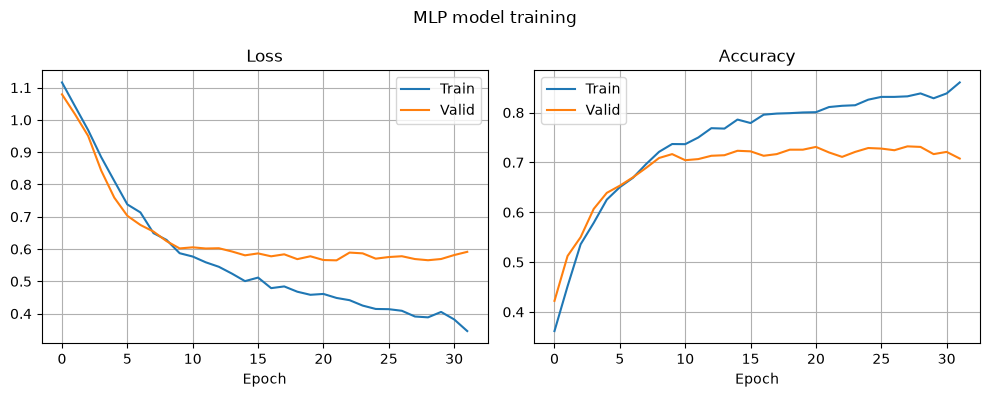

In [141]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Loss
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['valid_loss'], label='Valid')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['valid_acc'], label='Valid')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid()

fig.suptitle('MLP model training')
plt.tight_layout()
plt.show()


# Results Analysis for MLP

In [142]:
print(
    f"Train accuracy: {history['train_acc'][-1]:.4f}"
)
print(
    f"Valid accuracy: {history['valid_acc'][-1]:.4f}"
)

best_acc = max(history['valid_acc'])

print(f"Best validation accuracy: {best_acc:.4f}")

Train accuracy: 0.8605
Valid accuracy: 0.7078
Best validation accuracy: 0.7322


# CNN1D class

In [143]:

class CNN1D(nn.Module):

    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(6, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):

        # (batch, 28, 6) -> (batch, 6, 28)
        x = x.transpose(1, 2)

        x = self.features(x)
        x = x.squeeze(-1)

        return self.classifier(x)


## optimizer & scheduler

In [144]:
model = CNN1D().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

# Training CNN1D model
* using same data loaders and same fit()

## run training

In [145]:
model, history = fit(
    model=model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=100,
    patience=12,
    scheduler=scheduler
)

Epoch [001/100] | Train Loss: 1.0798 | Train Acc: 0.4325 | Valid Loss: 1.0172 | Valid Acc: 0.6367 | LR: 0.0010000 *
Epoch [002/100] | Train Loss: 0.8077 | Train Acc: 0.6970 | Valid Loss: 0.6114 | Valid Acc: 0.7200 | LR: 0.0010000 *
Epoch [003/100] | Train Loss: 0.5327 | Train Acc: 0.8033 | Valid Loss: 0.4414 | Valid Acc: 0.8711 | LR: 0.0010000 *
Epoch [004/100] | Train Loss: 0.4157 | Train Acc: 0.8577 | Valid Loss: 0.3308 | Valid Acc: 0.9133 | LR: 0.0010000 *
Epoch [005/100] | Train Loss: 0.3183 | Train Acc: 0.9071 | Valid Loss: 0.2501 | Valid Acc: 0.9378 | LR: 0.0010000 *
Epoch [006/100] | Train Loss: 0.2538 | Train Acc: 0.9255 | Valid Loss: 0.1937 | Valid Acc: 0.9567 | LR: 0.0010000 *
Epoch [007/100] | Train Loss: 0.2162 | Train Acc: 0.9372 | Valid Loss: 0.1554 | Valid Acc: 0.9678 | LR: 0.0010000 *
Epoch [008/100] | Train Loss: 0.1896 | Train Acc: 0.9431 | Valid Loss: 0.1401 | Valid Acc: 0.9644 | LR: 0.0010000 *
Epoch [009/100] | Train Loss: 0.1645 | Train Acc: 0.9565 | Valid Loss: 0

## see training history on graphs

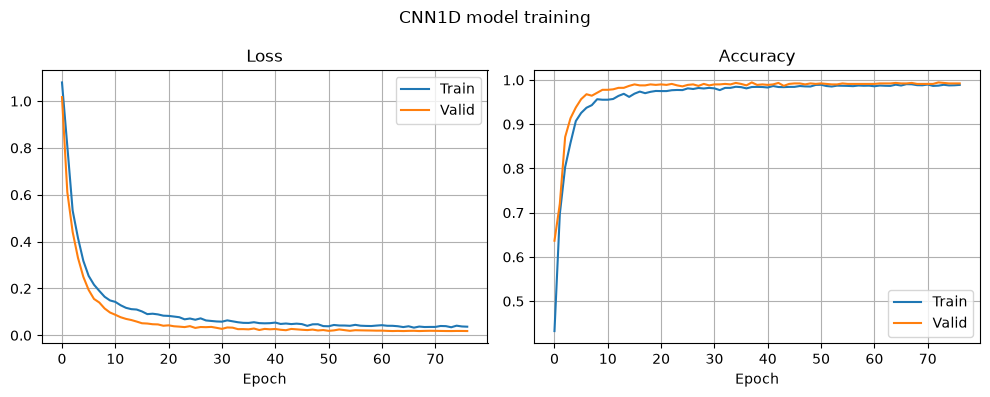

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Loss
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['valid_loss'], label='Valid')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['valid_acc'], label='Valid')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid()

fig.suptitle('CNN1D model training')
plt.tight_layout()
plt.show()


# Results Analysis for CNN1D

In [147]:
print(
    f"Train accuracy: {history['train_acc'][-1]:.4f}"
)
print(
    f"Valid accuracy: {history['valid_acc'][-1]:.4f}"
)

best_acc = max(history['valid_acc'])

print(f"Best validation accuracy: {best_acc:.4f}")

Train accuracy: 0.9888
Valid accuracy: 0.9922
Best validation accuracy: 0.9944


# Inference on new data 

## read test data

In [148]:
test_df = pd.read_csv('../data/data_C/test_signals.csv')
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   string  3500 non-null   str  
dtypes: str(1)
memory usage: 27.5 KB


In [149]:
test_df['string'].map(len).value_counts(dropna=False) 

string
28    3500
Name: count, dtype: int64

In [150]:
char_set = set()

for row in test_df['string']:
    char_set = char_set | set([ch for ch in row])

char_set

{'A', 'B', 'C', 'D', 'E', 'F'}

## data loader for inference

In [151]:
class LettersInferenceDataset(Dataset):

    def __init__(self, dataframe):

        self.letter_to_idx = {
            'A': 0,
            'B': 1,
            'C': 2,
            'D': 3,
            'E': 4,
            'F': 5
        }

        strings = dataframe['string'].tolist()

        indices = torch.tensor([
            [self.letter_to_idx[ch] for ch in s]
            for s in strings
        ], dtype=torch.long)

        self.X = torch.nn.functional.one_hot(
            indices,
            num_classes=6
        ).float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]

In [152]:
inference_dataset = LettersInferenceDataset(test_df)

inference_loader = DataLoader(
    inference_dataset,
    batch_size=32,
    shuffle=False
)

## predict function

In [153]:
def predict(model, loader, device):

    model.eval()

    predictions = []
    probabilities = []

    with torch.no_grad():

        for X_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(X_batch)

            probs = torch.softmax(outputs, dim=1)

            preds = outputs.argmax(dim=1)

            predictions.extend(preds.cpu().tolist())
            probabilities.extend(probs.cpu().tolist())

    return predictions, probabilities

## predict run

In [154]:
model.eval()

predictions, probabilities = predict(
    model,
    inference_loader,
    device
)

## predict save

In [155]:
answers_df = test_df.copy()

answers_df['source'] = predictions

answers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   string  3500 non-null   str  
 1   source  3500 non-null   int64
dtypes: int64(1), str(1)
memory usage: 54.8 KB


In [156]:
answers_df.to_csv('../results/answers.csv', index=False)